# Datafest 2026 · Team 1 · Propensión a la primera conversión

El equipo desarrolló **dos propuestas** independientes y las ponderó en una sola entrega.

* Propuesta A: un flujo completo de modelado, una auditoría del Gini y un LightGBM afinado con 12 variables.
* Propuesta B: un análisis de integridad de los datos, reglas dentro de cada banda de riesgo y siete fases de modelado.

Este cuaderno reúne ambos caminos, los vuelve a medir con el mismo protocolo, decide el modelo final y escribe el archivo submission.csv.

<table>
<thead><tr><th>Aspecto</th><th>Resumen</th></tr></thead>
<tbody><tr><td>Modelo final</td><td>Mezcla por rangos con pesos iguales (50 % y 50 %) de la propuesta A (LightGBM afinado, 12 variables, 5 semillas) y de la propuesta B (logística de reglas M1 y LightGBM monótono M3, 7 variables)</td></tr><tr><td>Motivo</td><td>La propuesta A gana en la ventana de selección (marzo a agosto) y la B en la de confirmación (septiembre a noviembre). Cada ventana favorece a la propuesta que la usó para diseñar su modelo. La mezcla no pierde en ninguna de las dos</td></tr><tr><td>Gini esperado en diciembre</td><td>Entre 0,24 y 0,26 aproximadamente; el error estándar de un solo mes está entre 0,009 y 0,015</td></tr><tr><td>Entrenamiento</td><td>Enero a noviembre de 2026, sin remuestreo y sin la variable dias_ultima_interaccion</td></tr></tbody>
</table>

Estructura del cuaderno:

1. Problema y datos.
2. Análisis exploratorio (EDA) de las dos propuestas.
3. Protocolo de validación.
4. Bitácora de experimentos de las dos propuestas.
5. Reevaluación conjunta con el mismo protocolo.
6. Decisión.
7. Entrenamiento final y archivo de entrega.
8. Conclusiones.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.optimize import minimize
from scipy.special import expit, logit
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from IPython.display import display, Image, Markdown

pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, VERDE, GRIS = "#2a6fdb", "#e8833a", "#2bb39b", "#888888"

DATA = Path("../data")
ART_R, ART_J = Path("artefactos_propuesta_a"), Path("artefactos_propuesta_b")
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")
print(train.shape, test.shape, sample.shape)

def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1

def rank01(p):
    return pd.Series(np.asarray(p)).rank(pct=True).values

(110100, 25) (9900, 24) (9900, 2)


## 1. Problema y datos

Cada fila es un cliente observado en un mes. La variable objetivo vale 1 cuando el cliente realiza su primera conversión en ese mes; después de convertir, el cliente no vuelve a aparecer.

Se entrena con los meses de enero a noviembre de 2026 y se predice diciembre de 2026. La métrica es el coeficiente de Gini, que equivale a dos veces el AUC menos uno; por tanto, solo importa el orden de los clientes dentro de diciembre.

En la práctica se trata de un modelo de supervivencia en tiempo discreto: cada mes, todo cliente que aún no ha convertido tiene una probabilidad mensual de hacerlo.

In [2]:
reglas = {
    "clientes que convierten más de una vez": int((train.groupby("id_cliente").objetivo.sum() > 1).sum()),
    "filas posteriores a la conversión": int((train.merge(train[train.objetivo == 1][["id_cliente", "mes"]].rename(columns={"mes": "mes_conv"}), on="id_cliente").query("mes > mes_conv")).shape[0]),
    "clientes de diciembre que ya convirtieron": int(test.id_cliente.isin(train.loc[train.objetivo == 1, "id_cliente"]).sum()),
}
ultimo = train.groupby("id_cliente").mes.max()
nunca = train.groupby("id_cliente").objetivo.sum() == 0
reglas["no convertidos que salen antes de noviembre"] = int((ultimo[nunca] < 202611).sum())
pd.Series(reglas, name="violaciones")

clientes que convierten más de una vez         0
filas posteriores a la conversión              0
clientes de diciembre que ya convirtieron      0
no convertidos que salen antes de noviembre    0
Name: violaciones, dtype: int64

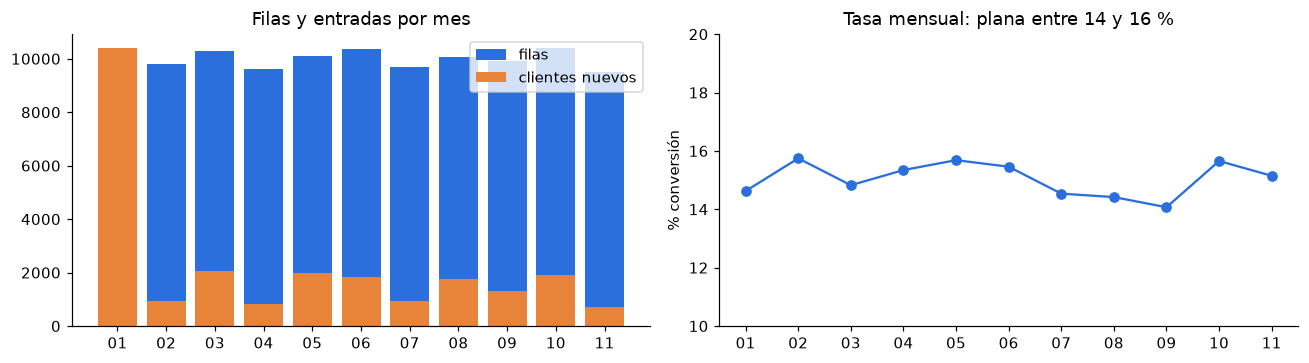

Diciembre: 9900 clientes = 8061 sobrevivientes de noviembre + 1839 nuevos


In [3]:
mensual = train.groupby("mes").agg(filas=("objetivo", "size"), tasa=("objetivo", "mean"))
primer = train.groupby("id_cliente").mes.min()
mensual["nuevos"] = primer.value_counts().sort_index()
dic_nuevos = (~test.id_cliente.isin(train.id_cliente)).sum()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(mensual.index.astype(str).str[-2:], mensual.filas, color=AZUL, label="filas")
ax[0].bar(mensual.index.astype(str).str[-2:], mensual.nuevos, color=NARANJA, label="clientes nuevos")
ax[0].set_title("Filas y entradas por mes"); ax[0].legend()
ax[1].plot(mensual.index.astype(str).str[-2:], mensual.tasa * 100, "o-", color=AZUL)
ax[1].set_ylim(10, 20); ax[1].set_ylabel("% conversión"); ax[1].set_title("Tasa mensual: plana entre 14 y 16 %")
plt.tight_layout(); plt.show()
print(f"Diciembre: {len(test)} clientes = {len(test) - dic_nuevos} sobrevivientes de noviembre + {dic_nuevos} nuevos")

**Lectura.** El panel cumple todas las reglas: nadie convierte dos veces, nadie aparece después de convertir y solo se sale del panel convirtiendo.

La tasa mensual es estable, entre el 14 % y el 16 %. En enero hay un grupo inicial de 10 400 clientes y después entran entre 900 y 2000 clientes nuevos por mes.

Diciembre está formado por los 8061 clientes que no convirtieron hasta noviembre y por 1839 clientes nuevos. Es, por tanto, una población de sobrevivientes, sesgada hacia probabilidades de conversión bajas.

## 2. Análisis exploratorio de las dos propuestas

### 2.1 Perfiles congelados

En un panel real, la edad, la antigüedad de la cuenta o los días desde la última transacción cambian de un mes a otro. En estos datos no ocurre así.

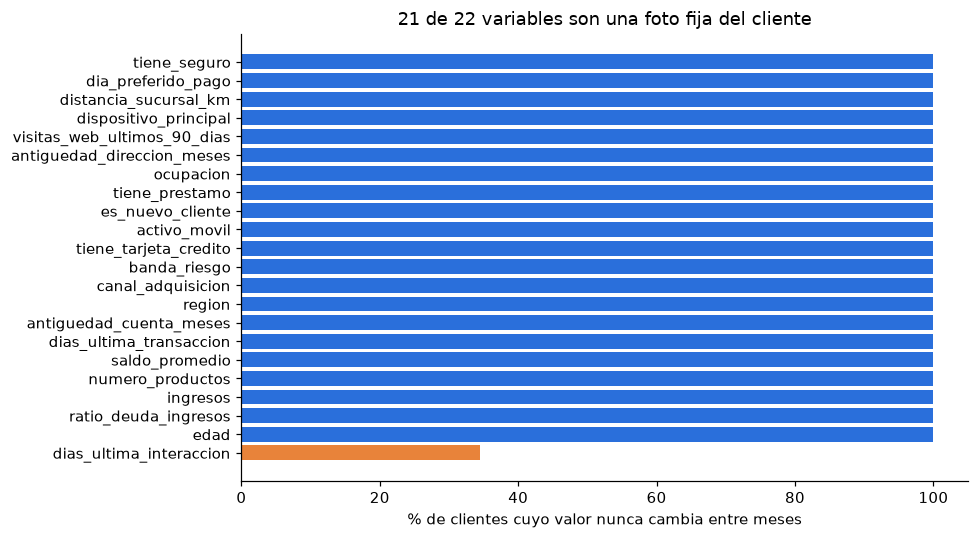

In [4]:
cols_pred = [c for c in train.columns if c not in ("id_cliente", "mes", "objetivo")]
fijas = {c: (train.groupby("id_cliente")[c].nunique() == 1).mean() * 100 for c in cols_pred}
fijas = pd.Series(fijas).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(fijas.index, fijas.values, color=[NARANJA if v < 100 else AZUL for v in fijas.values])
ax.set_xlabel("% de clientes cuyo valor nunca cambia entre meses"); ax.set_title("21 de 22 variables son una foto fija del cliente")
plt.tight_layout(); plt.show()

**Lectura.** Cada cliente es un perfil estático que se copia en cada mes hasta que convierte. La variable dias_ultima_transaccion no es una recencia que avance con el tiempo, sino un rasgo fijo del cliente.

En consecuencia, no hay tendencias, variaciones ni medias móviles individuales que construir. El problema consiste en ordenar perfiles según su probabilidad fija de conversión.

### 2.2 La única variable que cambia es una copia alterada

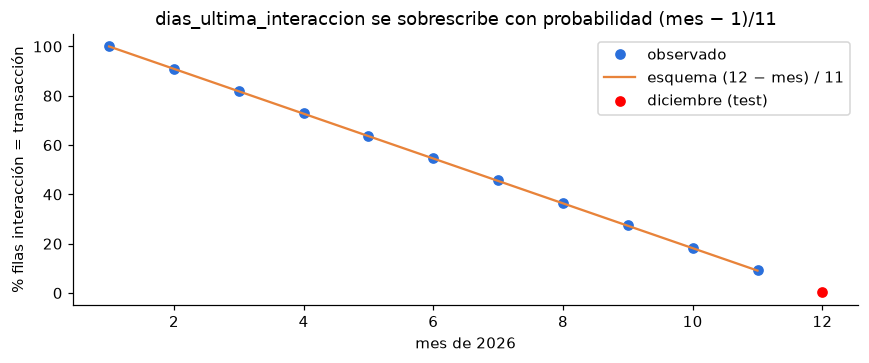

Gini univariante de dias_ultima_interaccion por mes: {202601: 0.076, 202602: 0.073, 202603: 0.093, 202604: 0.071, 202605: 0.063, 202606: 0.046, 202607: 0.066, 202608: 0.036, 202609: 0.041, 202610: 0.053, 202611: 0.017}


In [5]:
eq = train.assign(igual=train.dias_ultima_interaccion == train.dias_ultima_transaccion).groupby("mes").igual.mean()
m_idx = np.arange(1, 12)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(m_idx, eq.values * 100, "o", color=AZUL, label="observado")
ax.plot(m_idx, (1 - (m_idx - 1) / 11) * 100, "-", color=NARANJA, label="esquema (12 − mes) / 11")
ax.scatter([12], [(test.dias_ultima_interaccion == test.dias_ultima_transaccion).mean() * 100], color="red", label="diciembre (test)")
ax.set_xlabel("mes de 2026"); ax.set_ylabel("% filas interacción = transacción"); ax.legend(); ax.set_title("dias_ultima_interaccion se sobrescribe con probabilidad (mes − 1)/11")
plt.tight_layout(); plt.show()
g_int = train.groupby("mes").apply(lambda x: gini(x.objetivo, -x.dias_ultima_interaccion))
print("Gini univariante de dias_ultima_interaccion por mes:", g_int.round(3).to_dict())

**Lectura.** En enero las dos columnas son idénticas. Cada mes, una fracción igual a (m menos 1) dividido entre 11 se reemplaza por un valor al azar, y en diciembre prácticamente no queda ninguna coincidencia.

Su poder predictivo proviene de la variable de transacción y se desvanece mes a mes. En una prueba de estrés, el modelo que la incluía ganaba 0,002 de Gini en la muestra fuera de tiempo y perdía esa ganancia al permutarla, que es lo que ocurrirá en diciembre.

**Por ello se excluye de todos los modelos.**

### 2.3 Poder univariante y valor de información

In [6]:
iv = pd.read_csv(ART_R / "05_pruebas_estadisticas_iv.csv")[["variable", "gini_univariante", "iv", "poder_iv"]]
display(iv.round(4).head(12))

,variable,gini_univariante,iv,poder_iv
0,banda_riesgo,0.1612,0.1036,medio
1,numero_productos,0.1187,0.0503,débil
2,dias_ultima_transaccion,-0.0923,0.0278,débil
3,dias_ultima_interaccion,-0.0655,0.0143,sin poder
4,activo_movil,0.0420,0.0080,sin poder
5,ratio_deuda_ingresos,-0.0160,0.0027,sin poder
6,tiene_tarjeta_credito,0.0224,0.0027,sin poder
7,saldo_promedio,0.0167,0.0025,sin poder
8,antiguedad_cuenta_meses,0.0174,0.0015,sin poder
9,canal_adquisicion,0.0170,0.0011,sin poder


**Lectura.** Solo banda_riesgo alcanza un poder medio, con un valor de información de 0,10. Le siguen numero_productos y dias_ultima_transaccion; el resto queda por debajo de 0,02.

Es un problema de señal débil, por lo que desconfiamos de cualquier variable que prometa mucho más.

### 2.4 La señal actúa dentro de cada banda de riesgo

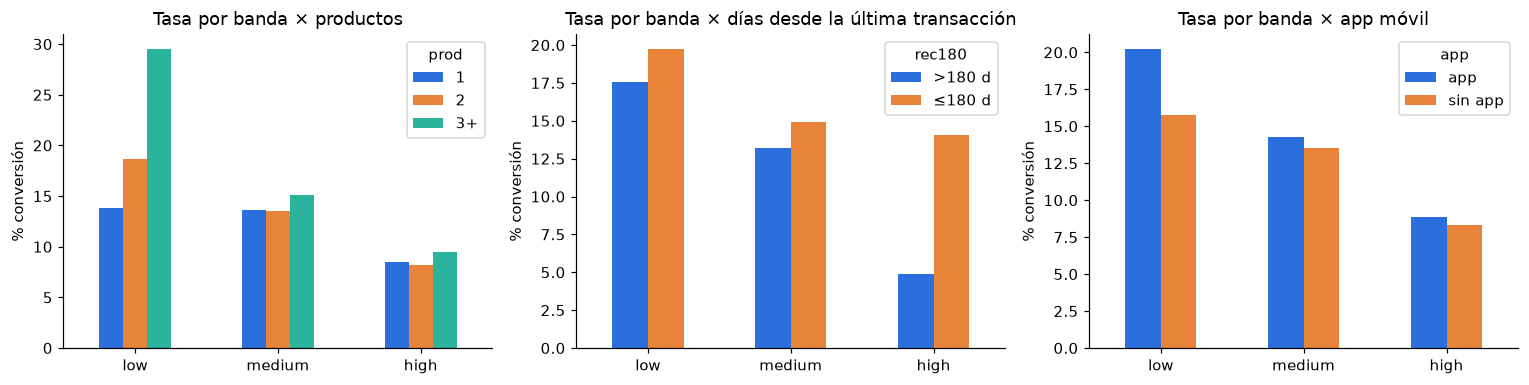

tasa  filas
banda_riesgo prod rec180              
low          1    >180 d  0.129  13266
                  ≤180 d  0.147  11972
             2    >180 d  0.176   7674
                  ≤180 d  0.197   7430
             3+   >180 d  0.281   5812
                  ≤180 d  0.310   5341
medium       1    >180 d  0.125   8101
                  ≤180 d  0.148   6968
             2    >180 d  0.132   5291
                  ≤180 d  0.140   5027
             3+   >180 d  0.142   5321
                  ≤180 d  0.161   4755
high         1    >180 d  0.049   5796
                  ≤180 d  0.136   4174
             2    >180 d  0.048   4063
                  ≤180 d  0.132   2761
             3+   >180 d  0.051   3721
                  ≤180 d  0.157   2627

In [7]:
t = train.assign(prod=np.minimum(train.numero_productos, 3).astype(str).replace({"3": "3+"}),
                 rec180=np.where(train.dias_ultima_transaccion > 180, ">180 d", "≤180 d"),
                 app=np.where(train.activo_movil, "app", "sin app"))
orden = ["low", "medium", "high"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col, titulo in zip(ax, ["prod", "rec180", "app"], ["productos", "días desde la última transacción", "app móvil"]):
    tab = t.pivot_table(index="banda_riesgo", columns=col, values="objetivo", aggfunc="mean").loc[orden] * 100
    tab.plot.bar(ax=a, rot=0, color=[AZUL, NARANJA, VERDE][: tab.shape[1]])
    a.set_title(f"Tasa por banda × {titulo}"); a.set_ylabel("% conversión"); a.set_xlabel("")
plt.tight_layout(); plt.show()
celdas = t.groupby(["banda_riesgo", "prod", "rec180"]).objetivo.agg(["mean", "size"]).round(3)
display(celdas.loc[orden].rename(columns={"mean": "tasa", "size": "filas"}))

**Lectura: las reglas ocultas en los datos.**

* Riesgo bajo: con tres o más productos, la tasa pasa de aproximadamente el 14 % al 29 %. La aplicación móvil solo suma cuando el cliente tiene dos o más productos.
* Riesgo alto: hay un escalón a los 180 días sin transacciones; la tasa cae de aproximadamente el 14 % al 5 %. Los productos y la aplicación casi no influyen.
* Riesgo medio: la tasa es casi plana.

Las reglas son interacciones de orden dos y tres, no efectos aditivos. Por eso un modelo lineal puro pierde cerca de 0,02 de Gini frente a los árboles o a las reglas explícitas.

La propuesta B las codificó como una regresión logística con reglas dentro de cada banda (modelo M1). La propuesta A las capturó con LightGBM y con las variables productos_x_riesgo_bajo y movil_y_tarjeta.

### 2.5 Comportamiento esperado de un banco frente a lo que muestran los datos

Este contraste también puede explorarse en la herramienta de visualización incluida en la carpeta visualizacion_eda, en las pestañas Variable audit e Integrity.

In [8]:
d1 = train.drop_duplicates("id_cliente")
contraste = pd.DataFrame([
    ("Ratio deuda/ingreso: con préstamo vs sin préstamo", "claramente mayor con préstamo",
     f"{d1[d1.tiene_prestamo].ratio_deuda_ingresos.mean():.3f} vs {d1[~d1.tiene_prestamo].ratio_deuda_ingresos.mean():.3f}"),
    ("Ratio deuda/ingreso: riesgo alto vs bajo", "riesgo alto más endeudado",
     f"{d1[d1.banda_riesgo=='high'].ratio_deuda_ingresos.mean():.3f} vs {d1[d1.banda_riesgo=='low'].ratio_deuda_ingresos.mean():.3f}"),
    ("Ingreso: manager vs manual", "brecha grande",
     f"{d1[d1.ocupacion=='manager'].ingresos.mean():,.0f} vs {d1[d1.ocupacion=='manual'].ingresos.mean():,.0f}"),
    ("`es_nuevo_cliente` con cuenta de 10+ años", "≈ 0 %", f"{d1[d1.antiguedad_cuenta_meses>=120].es_nuevo_cliente.mean():.1%}"),
    ("`es_nuevo_cliente` con cuenta ≤ 6 meses", "≈ 100 %", f"{d1[d1.antiguedad_cuenta_meses<=6].es_nuevo_cliente.mean():.1%}"),
    ("Cuenta abierta antes de los 18 años", "≈ 0 %", f"{((d1.edad - d1.antiguedad_cuenta_meses/12) < 18).mean():.1%}"),
    ("productos ≥ tarjeta + préstamo + seguro", "100 %",
     f"{(d1.numero_productos >= d1.tiene_tarjeta_credito.astype(int)+d1.tiene_prestamo.astype(int)+d1.tiene_seguro.astype(int)).mean():.1%}"),
], columns=["chequeo", "banco real", "en los datos"])
num = d1.select_dtypes("number").drop(columns=["id_cliente", "mes", "objetivo", "dias_ultima_interaccion"])
sp = num.corr("spearman").abs().values
np.fill_diagonal(sp, 0)
display(contraste)
print(f"Máxima |Spearman| entre dos variables numéricas distintas: {sp.max():.3f}")

,chequeo,banco real,en los datos
0,Ratio deuda/ingreso: con préstamo vs sin préstamo,claramente mayor con préstamo,0.326 vs 0.328
1,Ratio deuda/ingreso: riesgo alto vs bajo,riesgo alto más endeudado,0.329 vs 0.328
2,Ingreso: manager vs manual,brecha grande,"65,162 vs 65,224"
3,`es_nuevo_cliente` con cuenta de 10+ años,≈ 0 %,18.6%
4,`es_nuevo_cliente` con cuenta ≤ 6 meses,≈ 100 %,17.6%
5,Cuenta abierta antes de los 18 años,≈ 0 %,8.3%
6,productos ≥ tarjeta + préstamo + seguro,100 %,73.8%


Máxima |Spearman| entre dos variables numéricas distintas: 0.014


**Lectura.** Las variables se generaron de forma independiente entre sí: la mayor correlación de Spearman en valor absoluto es de 0,014. La banda de riesgo no se construye a partir de la deuda ni del ingreso; es una etiqueta externa, y la conversión se generó en torno a ella.

Por eso los ratios y combinaciones habituales en banca, como la deuda por producto o el saldo sobre el ingreso, no crean información: si sus componentes son ruido, la combinación también lo es.

### 2.6 Dificultad del objetivo

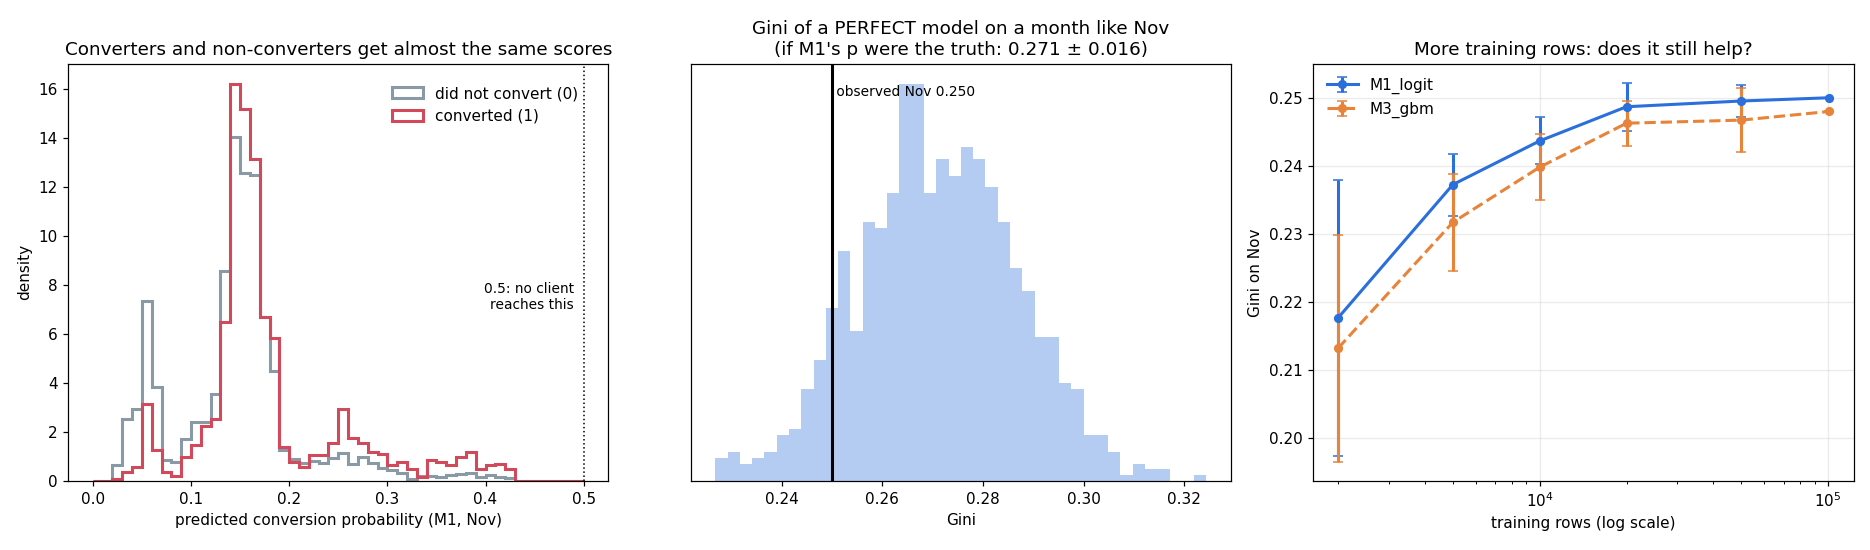

In [9]:
display(Image(ART_J / "figuras" / "difficulty.png", width=850))

**Lectura.** Ningún cliente alcanza una probabilidad mensual del 50 %. Un modelo perfecto, que conociera la probabilidad verdadera de cada cliente, obtendría un Gini cercano a 0,27 en un mes, con una variación de 0,015 en uno u otro sentido.

Los modelos razonables se sitúan entre 0,25 y 0,26: el techo está en los datos, no en el algoritmo.

## 3. Protocolo de validación

Se compararon ocho esquemas de validación con el mismo modelo campeón y con un modelo memorizador (un LightGBM sin regularizar). Lo importante es comprobar si cada esquema detecta que el memorizador es malo.

In [10]:
esq = pd.read_csv(ART_R / "17_comparacion_esquemas_validacion.csv")
display(esq.pivot_table(index="esquema", columns="modelo", values="gini_eval").round(4))

modelo,Campeón (12 vars),LGBM Optuna 6 vars,"Memorizador (LGBM sin regularizar, 21 vars)"
esquema,,,
A. VAL actual: 4 cortes expansivos (may–ago),0.2696,0.2626,0.1822
B. OOT actual: ene–ago -> sep–nov,0.2502,0.2502,0.1863
C. ene–oct -> nov (1 mes),0.2440,0.2388,0.2058
D. ene–sep -> oct–nov (2 meses),0.2526,0.2518,0.1972
"E. walk-forward 1 mes, todos (feb–nov, 10 cortes)",0.2647,0.2598,0.1734
"F. walk-forward 1 mes, solo jun–nov (≥5 meses train)",0.2587,0.2556,0.1860
G. StratifiedKFold por fila (5),0.2630,0.2605,0.1029
H. StratifiedGroupKFold por cliente (5),0.2651,0.2616,0.2267


**Lectura.** La validación aleatoria por filas y la agrupada por cliente prometen un Gini de 0,26 a 0,27 con el campeón y no castigan lo suficiente al memorizador. La razón es que ocho de cada diez clientes de un mes futuro ya se vieron antes, siempre sin conversión.

Por ello se adopta una validación temporal progresiva de un mes (conocida como walk forward): para cada mes m se entrena con todos los meses anteriores y se mide en m.

* Selección: promedio de marzo a agosto. Con esta ventana se elige el modelo.
* Confirmación: promedio de septiembre a noviembre. Es la muestra fuera de tiempo y solo se observa.
* Las diferencias de Gini menores que 0,009, que es el error estándar de un mes, se consideran empates, salvo que el bootstrap pareado indique lo contrario.

## 4. Bitácora de experimentos

### 4.1 Propuesta A

La propuesta A sigue la siguiente metodología, de principio a fin:

1. Definición del problema, de la población objetivo y del evento (primera conversión en el mes).
2. Particiones: desarrollo de enero a agosto, con entrenamiento y prueba agrupados por cliente, y muestra fuera de tiempo de septiembre a noviembre.
3. Auditoría de calidad, análisis univariado y bivariado, valor de información y estabilidad temporal mediante el índice de estabilidad poblacional (PSI).
4. Siete pruebas de fuga de información, entre ellas una validación adversarial.
5. Ingeniería de variables con una hipótesis de negocio escrita para cada variable.
6. Embudo de selección de 24 a 12 variables, con una regla de parsimonia.
7. Comparación de 11 modelos, optimización de hiperparámetros con Optuna y ablaciones.
8. Explicabilidad con SHAP y validación del sentido de negocio.
9. Calibración, puntaje de 0 a 1000 y niveles de prioridad.

Después se realizó una auditoría con unas 45 variantes y una validación temporal progresiva final.

**Comparación de modelos.** Desarrollo de enero a agosto con partición por cliente y muestra fuera de tiempo agrupada de septiembre a noviembre.

In [11]:
zoo = pd.read_csv(ART_R / "09_zoologico_modelos.csv")
display(zoo[["modelo", "gini_entrenamiento", "gini_prueba", "gini_oot", "brecha_entrenamiento_oot"]].sort_values("gini_oot", ascending=False).round(4))

,modelo,gini_entrenamiento,gini_prueba,gini_oot,brecha_entrenamiento_oot
0,Bosque aleatorio,0.4954,0.2551,0.2447,0.2507
1,Árbol de decisión,0.2859,0.2561,0.2439,0.0420
2,HistGradientBoosting,0.3153,0.2536,0.2420,0.0733
3,XGBoost,0.3798,0.2609,0.2418,0.1381
4,LightGBM,0.4106,0.2596,0.2413,0.1693
5,CatBoost,0.3681,0.2558,0.2413,0.1268
6,Regresión logística,0.2584,0.2441,0.2351,0.0233
7,SVM lineal,0.2564,0.2434,0.2336,0.0228
8,Scorecard WOE,0.2603,0.2425,0.2248,0.0355
9,k vecinos,0.2830,0.2400,0.2217,0.0613


**Ablaciones del modelo campeón:** variables, Optuna, peso de clase, SMOTE, monotonía, semillas y ensamble.

In [12]:
display(pd.read_csv(ART_R / "11_ablaciones.csv").round(4))

,ablacion,variante,gini_prueba,gini_oot,brier_oot,prob_media_oot
0,1. Variables,base completa,0.2573,0.2475,0.1268,0.0933
1,1. Variables,base con dias_ultima_interaccion,0.2567,0.2472,0.1268,0.0933
2,1. Variables,base con todas las variables nuevas,0.2575,0.2494,0.1265,0.0937
3,1. Variables,finalistas,0.2595,0.2496,0.1266,0.0928
4,2. Hiperparámetros,referencia,0.2596,0.2413,0.1233,0.1397
5,2. Hiperparámetros,Optuna,0.2595,0.2496,0.1266,0.0928
6,3. Desbalance,ninguno,0.2594,0.2488,0.1230,0.1410
7,3. Desbalance,peso balanceado (5.6),0.2615,0.2490,0.2195,0.4546
8,3. Desbalance,SMOTENC al 50%,0.2144,0.1968,0.1398,0.2553
9,4. Monotonía,sin restricciones,0.2595,0.2496,0.1266,0.0928


**Auditoría:** las variantes con mejor Gini en la muestra fuera de tiempo agrupada de septiembre a noviembre, con modelos entrenados de enero a agosto.

In [13]:
aud = pd.read_csv(ART_R / "17_auditoria_gini_resultados.csv")
display(aud[["name", "val_gini", "oot_gini", "oot_g9", "oot_g10", "oot_g11", "nfeat"]].sort_values("oot_gini", ascending=False).head(12).round(4))

,name,val_gini,oot_gini,oot_g9,oot_g10,oot_g11,nfeat
33,E1 promedio rangos: todos,0.2645,0.2539,0.2558,0.2631,0.2421,0
34,E2 LGBM campeón + logística reglas,0.2661,0.2536,0.2550,0.2610,0.2447,0
32,43 LGBM peso 1/(filas del cliente),0.2589,0.2534,0.2596,0.2625,0.2382,18
35,E3 LGBM bag + XGB + Cat + logit,0.2640,0.2534,0.2552,0.2622,0.2423,0
36,E4 lgb_w + logit + cat,0.2594,0.2532,0.2580,0.2619,0.2400,0
37,E5 ensamble pesos óptimos en VAL,0.2698,0.2523,0.2505,0.2618,0.2439,0
4,04 + interacción ventanas 3/6/9,0.2669,0.2522,0.2511,0.2627,0.2413,21
20,31 XGB logloss d3,0.2595,0.2519,0.2564,0.2601,0.2390,18
19,30 XGB rank:pairwise (≈ optimiza AUC),0.2486,0.2512,0.2533,0.2663,0.2327,18
6,11 LGBM 6 vars + reglas,0.2601,0.2511,0.2581,0.2584,0.2370,19


**Validación temporal progresiva final de la propuesta A**, con el mismo protocolo de este cuaderno.

In [14]:
display(pd.read_csv(ART_R / "20_plan_mejora_walkforward.csv"))

,modelo,seleccion_mar_ago,confirmacion_sep_nov,std_mensual,min_mensual,dif_sel_vs_campeon,ic95_sel,dif_conf_vs_campeon,ic95_conf,decision
0,Campeón LGBM 12 vars (5 semillas),0.2714,0.2508,0.0122,0.2435,0.0000,NaN,0.0000,NaN,referencia
1,XGB campeón + dir6 (30 vars),0.2721,0.2521,0.0120,0.2449,0.0008,[-0.0029;+0.0047],0.0013,[-0.0030;+0.0057],único positivo en ambos tramos; no significativo
2,XGB campeón 12 vars,0.2719,0.2510,0.0128,0.2445,0.0006,[-0.0008;+0.0020],0.0002,[-0.0013;+0.0015],empate
3,LGBM campeón + dir6,0.2711,0.2533,0.0111,0.2438,-0.0002,[-0.0035;+0.0033],0.0024,[-0.0019;+0.0063],no mejora selección
4,LGBM monótono (params campeón),0.2714,0.2530,0.0111,0.2423,-0.0000,[-0.0038;+0.0035],0.0020,[-0.0022;+0.0068],no mejora selección
5,LGBM búsqueda (40 pruebas),0.2731,0.2500,0.0121,0.2453,0.0017,[-0.0016;+0.0048],-0.0008,[-0.0056;+0.0038],sobreajuste a selección
6,LGBM monótono (params búsqueda),0.2722,0.2506,0.0115,0.2451,0.0007,[-0.0026;+0.0039],-0.0003,[-0.0051;+0.0044],descartado
7,Blend por rangos elegido en selección (168 pro...,0.2736,0.2505,0.0124,0.2455,0.0022,[-0.0003;+0.0046],-0.0003,[-0.0040;+0.0033],sobreajuste a selección
8,Mejor modelo con dir3 (3 variables del plan),0.2469,0.2305,0.0138,0.2090,NaN,NaN,NaN,NaN,pierde 0.025: faltan movil tarjeta y ratio
9,Mejor modelo con variables de mes y cohorte,0.2652,0.2506,0.0099,0.2376,NaN,NaN,NaN,NaN,sin aporte


**Mejor Gini de la propuesta A según la forma de medirlo**

<table>
<thead><tr><th>Medición</th><th>Mejor configuración</th><th>Gini</th></tr></thead>
<tbody><tr><td>Validación progresiva, selección de marzo a agosto</td><td>Campeón LightGBM con Optuna, 12 variables y 5 semillas</td><td>0,2714</td></tr><tr><td>Validación progresiva, confirmación de septiembre a noviembre</td><td>Ensamble E1 (promedio de rangos de 7 modelos)</td><td>0,2540</td></tr><tr><td>Ídem, un solo modelo</td><td>LightGBM campeón con dir6 o LightGBM monótono</td><td>0,2533 y 0,2530</td></tr><tr><td>Ídem, el campeón</td><td>Campeón con 12 variables</td><td>0,2508</td></tr><tr><td>Muestra fuera de tiempo agrupada, cuaderno original</td><td>Campeón con 12 variables</td><td>0,2490</td></tr></tbody>
</table>

El valor 0,2714 no corresponde a una muestra fuera de tiempo: es la ventana con la que se eligió el modelo. Además, Optuna se ajustó sobre los meses de mayo a agosto y el embudo de variables usó los de enero a agosto, por lo que esa cifra tiene un sesgo optimista.

En cuanto al ensamble E1, en la ventana de selección pierde 0,005 frente al campeón, con un intervalo de confianza que excluye el cero. Su ventaja en la muestra fuera de tiempo se debe al sesgo de selección, y por eso la propuesta A conservó el campeón.

### 4.2 Propuesta B

La propuesta B primero entendió cómo se generaron los datos (sección 2) y luego probó siete fases de modelado, siempre con validación progresiva de julio a noviembre y bootstrap pareado.

<table>
<thead><tr><th>Fase</th><th>Qué se probó</th><th>Mejor Gini de julio a noviembre</th><th>Veredicto</th></tr></thead>
<tbody><tr><td>2</td><td>Logística de reglas por banda (M1), tabla de celdas, LightGBM monótono (M3) y mezclas</td><td>0,2573 (M1 y M3)</td><td>M1 y M3 empatan; la mezcla es la más estable</td></tr><tr><td>3</td><td>20 variables habituales en banca y XGBoost con Optuna (60 pruebas)</td><td>0,2612 en validación cruzada, 0,2355 en noviembre</td><td>El ajuste de hiperparámetros no se sostiene en la muestra reservada</td></tr><tr><td>4</td><td>Estacionalidad peruana: gratificación, CTS, feriados y quincena</td><td>0,2550</td><td>No suma y perjudica cuando una estación se vio una sola vez</td></tr><tr><td>5</td><td>Espacios latentes: autocodificador, SCARF y SupCon</td><td>0,249</td><td>Ninguna representación supera a la red entrenada directamente</td></tr><tr><td>6</td><td>Todos los modelos con submuestreo y sobremuestreo</td><td>0,2577 (M1, M3 y XGBoost)</td><td>El remuestreo nunca ayuda y descalibra</td></tr><tr><td>7</td><td>Supervivencia: Cox, Weibull y XGBoost AFT</td><td>0,2552</td><td>Es matemáticamente el mismo modelo y empata</td></tr></tbody>
</table>

,model,gini_07,gini_08,gini_09,gini_10,gini_11,gini_mean,gini_sd
24,XGB_raw,0.2747,0.2672,0.2509,0.2689,0.2307,0.2585,0.0179
44,blend M1+M3+XGB_rule7,0.2650,0.2593,0.2535,0.2642,0.2462,0.2577,0.0079
40,blend M1+M3,0.2637,0.2573,0.2518,0.2623,0.2516,0.2573,0.0057
16,M3_lgbm,0.2667,0.2547,0.2489,0.2617,0.2484,0.2561,0.0080
20,XGB_rule7,0.2633,0.2604,0.2553,0.2655,0.2355,0.2560,0.0121
28,XGB_built,0.2728,0.2584,0.2504,0.2637,0.2316,0.2554,0.0156
0,M1_logit,0.2575,0.2557,0.2512,0.2607,0.2500,0.2550,0.0044
32,XGB_rule7_calendar,0.2653,0.2582,0.2505,0.2646,0.2363,0.2550,0.0121
4,M1_log,0.2569,0.2558,0.2514,0.2610,0.2497,0.2550,0.0045
36,M4_blend (M1+M2+M3),0.2619,0.2565,0.2479,0.2639,0.2427,0.2546,0.0091


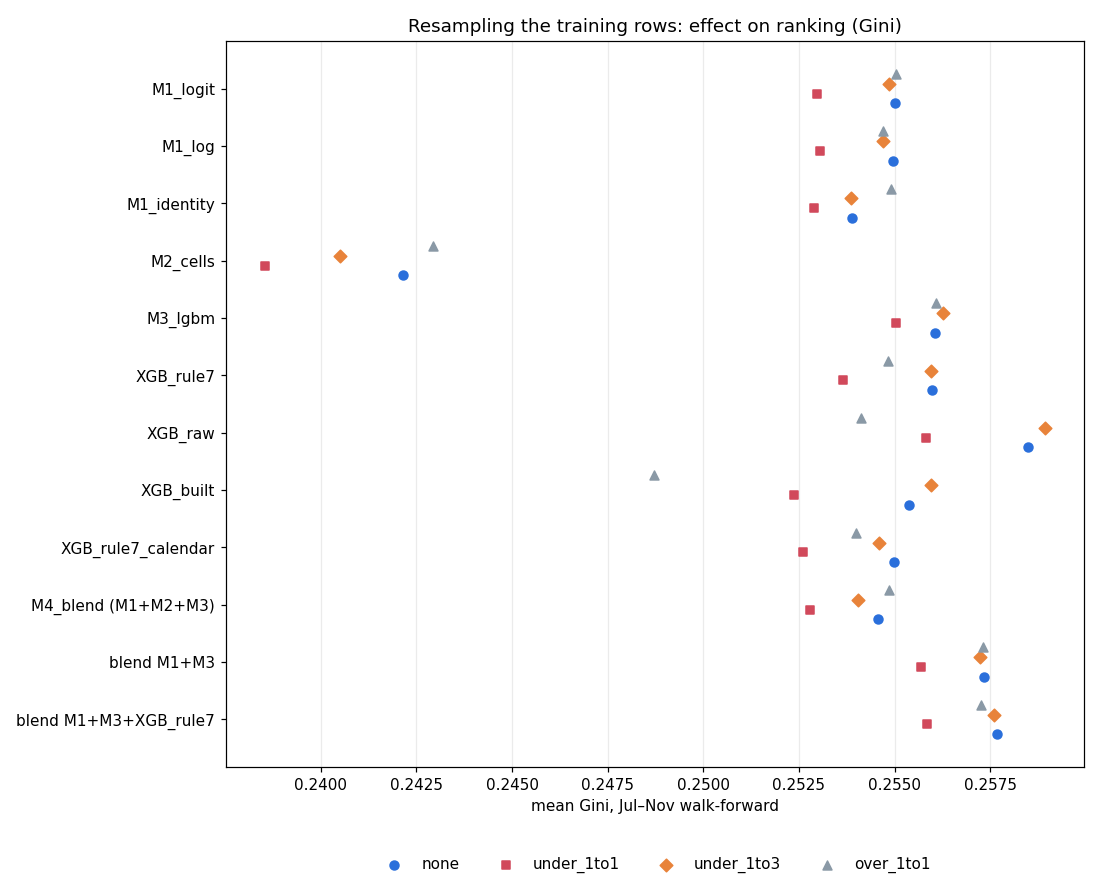

In [15]:
p6 = pd.read_csv(ART_J / "phase6_summary.csv")
display(p6[p6.strategy == "none"][["model", "gini_07", "gini_08", "gini_09", "gini_10", "gini_11", "gini_mean", "gini_sd"]].sort_values("gini_mean", ascending=False).round(4))
display(Image(ART_J / "figuras" / "resampling_gini.png", width=850))

## 5. Reevaluación conjunta con el mismo protocolo

Las cifras de las dos propuestas provienen de ventanas distintas, por lo que no pueden compararse directamente. Aquí se reentrenan los finalistas con exactamente la misma validación progresiva, mes a mes, de marzo a noviembre:

* A: campeón de la propuesta A, LightGBM con los hiperparámetros de Optuna, 12 variables y 5 semillas.
* M1 de la propuesta B: logística de reglas con enlace logit, reglas repetidas dentro de cada banda y efectos fijos de mes.
* M3 de la propuesta B: LightGBM poco profundo, monótono decreciente en recencia y deuda, con 3 semillas.
* B: mezcla de la propuesta B, es decir, el promedio de rangos de M1 y M3.
* Mezcla A+B: promedio de rangos de A y de B.

In [16]:
CATEG = ["ocupacion", "region", "canal_adquisicion", "banda_riesgo", "dispositivo_principal"]
d = pd.concat([train, test.assign(objetivo=np.nan)], ignore_index=True)
for c in CATEG:
    d[c] = pd.Categorical(d[c], categories=sorted(train[c].unique()))
d["productos_x_riesgo_bajo"] = d.numero_productos * (d.banda_riesgo == "low").astype(int)
d["movil_y_tarjeta"] = (d.activo_movil & d.tiene_tarjeta_credito).astype(int)

# ---- Propuesta A: LightGBM afinado (artefactos_propuesta_a/16_resumen_final.json)
resumen_a = json.load(open(ART_R / "16_resumen_final.json"))
VARS_A = resumen_a["variables_finales"]
PARAMS_A = {k: v for k, v in resumen_a["hiperparametros"].items() if k != "random_state"}
print("Variables de la propuesta A:", VARS_A)

def modelo_a(tr, te, seeds=(42, 43, 44, 45, 46)):
    return np.mean([lgb.LGBMClassifier(**PARAMS_A, random_state=s).fit(tr[VARS_A], tr.objetivo.astype(int))
                    .predict_proba(te[VARS_A])[:, 1] for s in seeds], axis=0)

# ---- Propuesta B: M1 logística de reglas por banda (enlace logit)
BANDAS = ["low", "medium", "high"]
def diseno_reglas(x):
    prod, app, rec = x.numero_productos.values, x.activo_movil.astype(int).values, x.dias_ultima_transaccion.values
    g = {"uno": np.ones(len(x)), "prod2": prod == 2, "prod3p": prod >= 3, "app": app, "app_prod2": app * (prod == 2),
         "app_prod3p": app * (prod >= 3), "tarjeta": x.tiene_tarjeta_credito.astype(int).values, "rec_lin": rec / 365,
         "rec_gt181": rec > 181, "deuda_alta_sin_app": (x.ratio_deuda_ingresos.values > 0.55) & (app == 0),
         "sucursal": (x.canal_adquisicion.astype(str) == "branch").values}
    return pd.DataFrame({f"{b}:{k}": (x.banda_riesgo.astype(str).values == b) * np.asarray(v, float)
                         for b in BANDAS for k, v in g.items()}, index=x.index)

class M1:
    def fit(self, x, l2=1.0):
        X = diseno_reglas(x); self.cols = list(X.columns)
        meses = sorted(x.mes.unique())[1:]
        Xm = np.hstack([X.values, np.column_stack([(x.mes.values == m) for m in meses]).astype(float)]) if meses else X.values
        y = x.objetivo.values.astype(float)
        def f(w):
            p = np.clip(expit(Xm @ w), 1e-6, 1 - 1e-6)
            return -(y * np.log(p) + (1 - y) * np.log(1 - p)).sum() + 0.5 * l2 * w @ w, Xm.T @ (p - y) + l2 * w
        self.w = minimize(f, np.zeros(Xm.shape[1]), jac=True, method="L-BFGS-B", options={"maxiter": 2000}).x
        return self
    def predict(self, x):
        return expit(diseno_reglas(x).values @ self.w[: len(self.cols)])
    def coefs(self):
        return pd.Series(self.w[: len(self.cols)], index=self.cols)

# ---- Propuesta B: M3 LightGBM poco profundo y monótono sobre las 7 variables
def base7(x):
    return pd.DataFrame({"banda": x.banda_riesgo.astype(str).map({b: i for i, b in enumerate(BANDAS)}).astype(int),
                         "productos": x.numero_productos, "recencia": x.dias_ultima_transaccion.astype(float),
                         "app": x.activo_movil.astype(int), "tarjeta": x.tiene_tarjeta_credito.astype(int),
                         "deuda": x.ratio_deuda_ingresos, "sucursal": (x.canal_adquisicion.astype(str) == "branch").astype(int)}, index=x.index)

def modelo_m3(tr, te, seeds=(0, 1, 2)):
    Xtr, Xte = base7(tr), base7(te)
    mono = [{"recencia": -1, "deuda": -1}.get(c, 0) for c in Xtr.columns]
    return np.mean([lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, max_depth=3, num_leaves=8, min_child_samples=200,
                                       reg_lambda=10.0, subsample=0.8, subsample_freq=1, monotone_constraints=mono,
                                       monotone_constraints_method="advanced", random_state=s, verbose=-1)
                    .fit(Xtr, tr.objetivo.astype(int)).predict_proba(Xte)[:, 1] for s in seeds], axis=0)

def todos_los_modelos(tr, te):
    r, m1, m3 = modelo_a(tr, te), M1().fit(tr).predict(te), modelo_m3(tr, te)
    j = 0.5 * rank01(m1) + 0.5 * rank01(m3)
    return {"A: LightGBM afinado": r, "B-M1 reglas": m1, "B-M3 LGBM monótono": m3, "B: reglas + LGBM monótono": j,
            "Mezcla A+B": 0.5 * rank01(r) + 0.5 * rank01(j)}

Variables de la propuesta A: ['productos_x_riesgo_bajo', 'banda_riesgo', 'dias_ultima_transaccion', 'movil_y_tarjeta', 'numero_productos', 'ratio_deuda_ingresos', 'saldo_promedio', 'antiguedad_cuenta_meses', 'ingresos', 'distancia_sucursal_km', 'edad', 'canal_adquisicion']


In [17]:
MESES = [202603, 202604, 202605, 202606, 202607, 202608, 202609, 202610, 202611]
SEL, CONF = MESES[:6], MESES[6:]
filas, oof = [], []
for m in MESES:
    tr, te = d[d.mes < m], d[d.mes == m]
    for nombre, p in todos_los_modelos(tr, te).items():
        filas.append({"modelo": nombre, "mes": m, "gini": gini(te.objetivo.astype(int), p)})
        oof.append(pd.DataFrame({"modelo": nombre, "mes": m, "fila": te.index, "y": te.objetivo.astype(int).values,
                                 "p": p, "sobreviviente": te.id_cliente.isin(d.loc[d.mes < m, "id_cliente"]).values}))
gm = pd.DataFrame(filas).pivot(index="modelo", columns="mes", values="gini")
oof = pd.concat(oof, ignore_index=True)
tabla = pd.DataFrame({"selección mar–ago": gm[SEL].mean(1), "confirmación sep–nov": gm[CONF].mean(1),
                      "jul–nov": gm[MESES[4:]].mean(1), "noviembre": gm[202611], "desvío mensual": gm.std(1),
                      "peor mes": gm.min(1)}).sort_values("selección mar–ago", ascending=False)
display(tabla.round(4))
display(gm.round(4))

,selección mar–ago,confirmación sep–nov,jul–nov,noviembre,desvío mensual,peor mes
modelo,,,,,,
A: LightGBM afinado,0.2714,0.2508,0.2592,0.2436,0.0130,0.2436
Mezcla A+B,0.2697,0.2544,0.2601,0.2495,0.0099,0.2495
B: reglas + LGBM monótono,0.2630,0.2552,0.2573,0.2516,0.0064,0.2516
B-M3 LGBM monótono,0.2628,0.2530,0.2561,0.2484,0.0072,0.2484
B-M1 reglas,0.2587,0.2540,0.2550,0.2500,0.0069,0.2497


mes,202603,202604,202605,202606,202607,202608,202609,202610,202611
modelo,,,,,,,,,
B: reglas + LGBM monótono,0.2679,0.2610,0.2700,0.2579,0.2637,0.2573,0.2518,0.2623,0.2516
B-M1 reglas,0.2648,0.2545,0.2698,0.2497,0.2575,0.2557,0.2512,0.2607,0.2500
B-M3 LGBM monótono,0.2642,0.2642,0.2665,0.2607,0.2667,0.2547,0.2489,0.2617,0.2484
A: LightGBM afinado,0.2759,0.2744,0.2780,0.2564,0.2753,0.2682,0.2471,0.2616,0.2436
Mezcla A+B,0.2754,0.2696,0.2762,0.2599,0.2722,0.2650,0.2503,0.2635,0.2495


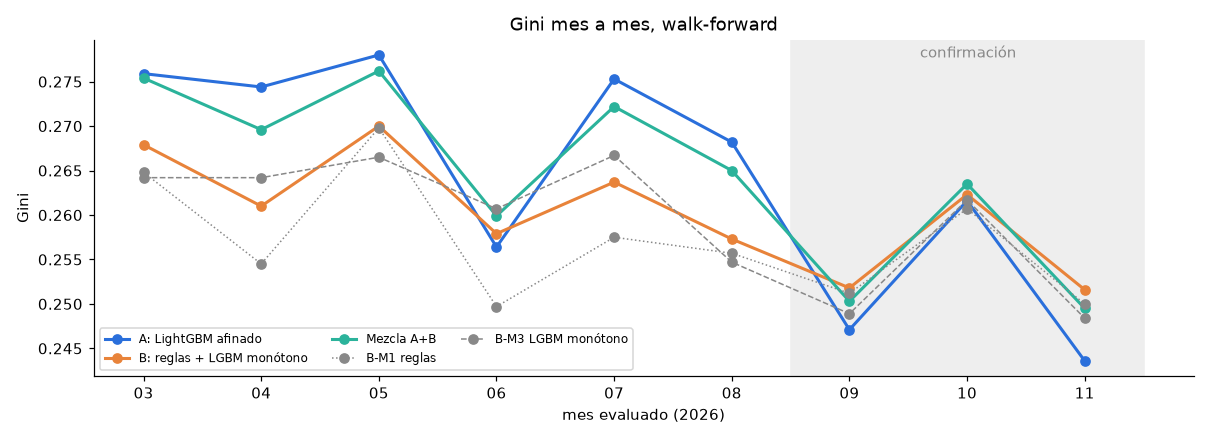

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))
estilos = {"A: LightGBM afinado": (AZUL, "-"), "B: reglas + LGBM monótono": (NARANJA, "-"), "Mezcla A+B": (VERDE, "-"),
           "B-M1 reglas": (GRIS, ":"), "B-M3 LGBM monótono": (GRIS, "--")}
for n, (c, ls) in estilos.items():
    ax.plot([str(m)[-2:] for m in MESES], gm.loc[n].values, ls, marker="o", color=c, label=n, lw=2 if c != GRIS else 1)
ax.axvspan(5.5, 8.5, color="#eeeeee", zorder=0); ax.text(6.6, ax.get_ylim()[1] - 0.002, "confirmación", color=GRIS)
ax.set_xlabel("mes evaluado (2026)"); ax.set_ylabel("Gini"); ax.legend(ncol=3, fontsize=8); ax.set_title("Gini mes a mes, walk-forward")
plt.tight_layout(); plt.show()

**Bootstrap pareado.** Se remuestrean las mismas filas de cada mes para los dos modelos comparados y se calcula la diferencia del Gini medio con su intervalo de confianza del 95 %.

In [19]:
rng = np.random.default_rng(0)
def boot(a, b, meses, n=400):
    A = oof[oof.modelo == a].set_index(["mes", "fila"]); B = oof[oof.modelo == b].set_index(["mes", "fila"])
    difs = []
    for _ in range(n):
        dd = []
        for m in meses:
            x, z = A.loc[m], B.loc[m]; ix = rng.integers(0, len(x), len(x)); y = x.y.values[ix]
            dd.append(gini(y, x.p.values[ix]) - gini(y, z.p.values[ix]))
        difs.append(np.mean(dd))
    difs = np.array(difs)
    return difs.mean(), np.percentile(difs, 2.5), np.percentile(difs, 97.5), (difs > 0).mean()
comp = []
for a, b in [("B: reglas + LGBM monótono", "A: LightGBM afinado"), ("Mezcla A+B", "A: LightGBM afinado"), ("Mezcla A+B", "B: reglas + LGBM monótono")]:
    for tramo, meses in [("selección", SEL), ("confirmación", CONF)]:
        mu, lo, hi, pm = boot(a, b, meses)
        comp.append({"comparación": f"{a} − {b}", "tramo": tramo, "diferencia": mu, "IC95 inf": lo, "IC95 sup": hi, "P(mejor)": pm})
display(pd.DataFrame(comp).round(4))

,comparación,tramo,diferencia,IC95 inf,IC95 sup,P(mejor)
0,B: reglas + LGBM monótono − A: LightGBM afinado,selección,-0.0083,-0.0140,-0.0024,0.0000
1,B: reglas + LGBM monótono − A: LightGBM afinado,confirmación,0.0045,-0.0032,0.0116,0.8675
2,Mezcla A+B − A: LightGBM afinado,selección,-0.0015,-0.0046,0.0017,0.1850
3,Mezcla A+B − A: LightGBM afinado,confirmación,0.0037,0.0001,0.0073,0.9750
4,Mezcla A+B − B: reglas + LGBM monótono,selección,0.0068,0.0037,0.0097,1.0000
5,Mezcla A+B − B: reglas + LGBM monótono,confirmación,-0.0008,-0.0049,0.0032,0.3700


**Comprobación con una población similar a la de diciembre.** Como el 81 % de diciembre son sobrevivientes, se mide cada modelo por separado en los sobrevivientes y en los clientes nuevos de la ventana de confirmación.

In [20]:
sub = oof[oof.mes.isin(CONF)].groupby(["modelo", "sobreviviente"]).apply(
    lambda x: np.mean([gini(g.y, g.p) for _, g in x.groupby("mes")])).unstack()
sub.columns = ["nuevos", "sobrevivientes"]
display(sub.round(4))

,nuevos,sobrevivientes
modelo,,
B: reglas + LGBM monótono,0.2358,0.2526
B-M1 reglas,0.2354,0.2510
B-M3 LGBM monótono,0.2334,0.2502
A: LightGBM afinado,0.2414,0.2465
Mezcla A+B,0.2392,0.2510


## 6. Decisión

<table>
<thead><tr><th>Comparación con bootstrap pareado</th><th>Selección (marzo a agosto)</th><th>Confirmación (septiembre a noviembre)</th></tr></thead>
<tbody><tr><td>B frente a A</td><td>B pierde 0,008; el intervalo excluye el cero, gana A</td><td>B gana 0,005; el intervalo incluye el cero, empate</td></tr><tr><td>Mezcla A+B frente a A</td><td>La mezcla pierde 0,0015; el intervalo incluye el cero, empate</td><td><b>La mezcla gana 0,004; el intervalo excluye el cero</b></td></tr><tr><td>Mezcla A+B frente a B</td><td><b>La mezcla gana 0,007; el intervalo excluye el cero</b></td><td>La mezcla pierde 0,001; el intervalo incluye el cero, empate</td></tr></tbody>
</table>

Las cifras exactas figuran en la tabla de la sección 5.

* A gana la selección y B gana la confirmación. Cada ventana favorece a una de las propuestas: el campeón de A se afinó con Optuna y con el embudo de variables dentro de los meses de enero a agosto, mientras que las reglas de B se descubrieron observando los meses de enero a noviembre, incluida la confirmación. Elegir una sola propuesta por cualquiera de las dos ventanas premiaría a la que la usó para diseñar.
* La mezcla A+B no pierde en ninguna ventana y supera de forma significativa a cada propuesta en la ventana donde esa propuesta es débil: empata con A en selección y la supera en confirmación; supera a B en selección y empata con ella en confirmación.
* Además, es más estable que el campeón (desviación mensual de 0,010 frente a 0,013) y mejora en noviembre y en los sobrevivientes, que representan el 81 % de diciembre.
* Combina dos tipos de modelo distintos, con una correlación de Spearman de 0,92 entre ellos: un árbol afinado sobre 12 variables y reglas explícitas con monotonía sobre 7. Las reglas aportan la estructura encontrada en el análisis exploratorio (sección 2.4), y el árbol aporta lo que la búsqueda de A capturó, con su ruido diluido.

**Entrega final del Team 1: la mezcla A+B, promedio de rangos con pesos iguales de las dos propuestas, entrenada con los meses de enero a noviembre.**

Para entregar probabilidades y no rangos se aplica un mapeo por cuantiles:

1. El campeón de A se calibra con el método de Platt, usando sus predicciones fuera de muestra de septiembre a noviembre.
2. A cada cliente de diciembre se le asigna la probabilidad calibrada que ocupa su misma posición en la mezcla.

Así, el orden y por tanto el Gini son los de la mezcla, y la escala es la de un modelo calibrado.

## 7. Entrenamiento final y archivo de entrega

In [21]:
conf_r = oof[(oof.modelo == "A: LightGBM afinado") & oof.mes.isin(CONF)]
lg = lambda p: logit(np.clip(p, 1e-6, 1 - 1e-6)).reshape(-1, 1)
platt_r = LogisticRegression(C=1e6).fit(lg(conf_r.p.values), conf_r.y.values)
print(f"Platt del campeón en sep–nov: media predicha {platt_r.predict_proba(lg(conf_r.p.values))[:, 1].mean():.3f} vs tasa observada {conf_r.y.mean():.3f}")

tr, te = d[d.mes <= 202611], d[d.mes == 202612]
preds = todos_los_modelos(tr, te)
score = preds["Mezcla A+B"]
prob_r = np.sort(platt_r.predict_proba(lg(preds["A: LightGBM afinado"]))[:, 1])
orden_rj = pd.Series(score).rank(method="first").values.astype(int) - 1
prob = prob_r[orden_rj]          # misma escala que el campeón calibrado, orden de la mezcla
submission = pd.DataFrame({"id_cliente": te.id_cliente.values, "prediccion": prob})
submission.to_csv("submission.csv", index=False)

m1_final = M1().fit(tr)
print("Coeficientes de la logística de reglas (log-odds), entrenada ene–nov:")
cf = m1_final.coefs()
cf.index = pd.MultiIndex.from_tuples([tuple(i.split(":")) for i in cf.index], names=["banda", "regla"])
display(cf.unstack("banda")[BANDAS].round(3))

Platt del campeón en sep–nov: media predicha 0.150 vs tasa observada 0.150


Coeficientes de la logística de reglas (log-odds), entrenada ene–nov:


banda,low,medium,high
regla,,,
app,0.011,-0.037,0.164
app_prod2,0.526,0.029,-0.347
app_prod3p,0.523,0.128,-0.059
deuda_alta_sin_app,-0.474,-0.499,-0.313
prod2,0.029,-0.023,0.194
prod3p,0.662,0.037,0.147
rec_gt181,0.047,0.052,-0.869
rec_lin,-0.386,-0.377,-0.613
sucursal,-0.030,-0.024,-0.592


,valor
filas,9900
mismo orden e ids que sample_submission,True
columnas,"[id_cliente, prediccion]"
"prediccion en [0, 1]",True
nulos,0
min / media / max,0.034 / 0.150 / 0.485
media sobrevivientes / nuevos,0.144 / 0.176
Spearman probabilidad entregada vs mezcla (debe ser 1),1.0
Spearman con A,0.979
Spearman con B,0.979


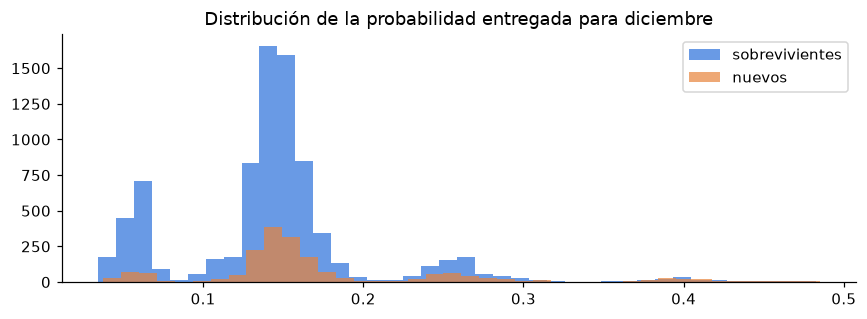

,id_cliente,prediccion
0,2,0.150074
1,3,0.062009
2,7,0.145821
3,10,0.059698
4,11,0.151376


In [22]:
sobrev = te.id_cliente.isin(train.id_cliente).values
checks = pd.Series({
    "filas": len(submission),
    "mismo orden e ids que sample_submission": bool((submission.id_cliente.values == sample.id_cliente.values).all()),
    "columnas": list(submission.columns),
    "prediccion en [0, 1]": bool(submission.prediccion.between(0, 1).all()),
    "nulos": int(submission.prediccion.isna().sum()),
    "min / media / max": f"{prob.min():.3f} / {prob.mean():.3f} / {prob.max():.3f}",
    "media sobrevivientes / nuevos": f"{prob[sobrev].mean():.3f} / {prob[~sobrev].mean():.3f}",
    "Spearman probabilidad entregada vs mezcla (debe ser 1)": round(pd.Series(prob).corr(pd.Series(score), method="spearman"), 6),
    "Spearman con A": round(pd.Series(score).corr(pd.Series(preds["A: LightGBM afinado"]), method="spearman"), 4),
    "Spearman con B": round(pd.Series(score).corr(pd.Series(preds["B: reglas + LGBM monótono"]), method="spearman"), 4),
    "Spearman A vs B": round(pd.Series(preds["A: LightGBM afinado"]).corr(pd.Series(preds["B: reglas + LGBM monótono"]), method="spearman"), 4),
})
display(checks.to_frame("valor"))
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(prob[sobrev], bins=40, alpha=0.7, color=AZUL, label="sobrevivientes"); ax.hist(prob[~sobrev], bins=40, alpha=0.7, color=NARANJA, label="nuevos")
ax.set_title("Distribución de la probabilidad entregada para diciembre"); ax.legend(); plt.tight_layout(); plt.show()
submission.head()

## 8. Conclusiones

1. Los datos son sintéticos y estáticos. Veintiuna de las veintidós variables no cambian por cliente, y la única que cambia, dias_ultima_interaccion, se sobrescribe al azar según el calendario. Por eso se excluye.
2. La señal está formada por reglas dentro de cada banda de riesgo sobre siete variables: banda, productos, días desde la última transacción (con un escalón en 180 días para el riesgo alto), aplicación móvil, tarjeta, deuda sin aplicación y canal de sucursal.
3. El techo es de aproximadamente 0,27, que es el Gini de un modelo perfecto en un mes. Todos los modelos razonables del equipo se sitúan entre 0,25 y 0,26 en la validación progresiva, y las diferencias entre ellos son menores que el ruido de un mes.
4. La validación adecuada es la temporal progresiva de un mes. La validación aleatoria por filas o por cliente sobreestima el Gini y no detecta la memorización.
5. Lo que no funcionó, y quedó documentado: el ajuste agresivo de hiperparámetros, las variables habituales en banca, la estacionalidad, el remuestreo, los espacios latentes, la supervivencia en tiempo continuo, la pérdida focal y el ordenamiento por pares.
6. La entrega es la mezcla por rangos de las dos propuestas. Se espera un Gini de entre 0,24 y 0,26 en diciembre.